In [1]:
import numpy as np
import json
import cv2

from copy import deepcopy
from scipy.optimize import minimize
from pathlib import Path

In [2]:
# Paths
experiment_name = 'tomato_soup_can'
path_before = Path(f'/workspace/Neo/data/{experiment_name}_before')
path_after = Path(f'/workspace/Neo/data/{experiment_name}_after')

# experiment_name = 'tomato_soup_can'
# path_before = Path(f'/workspace/Neo/data/{experiment_name}_before')
# path_after = Path(f'/workspace/Neo/data/{experiment_name}_before')

In [3]:
# Load transformation
with open(path_before / 'transforms copy.json', 'r') as file:
    transforms_before = json.load(file)

with open(path_after / 'transforms copy.json', 'r') as file:
    transforms_after = json.load(file)

In [4]:
# Load images
images_before = []
for frame in transforms_before["frames"]:
    images_before.append(cv2.imread(str(path_before / frame["file_path"])))

images_after = []
for frame in transforms_after["frames"]:
    images_after.append(cv2.imread(str(path_after / frame["file_path"])))

In [5]:
def get_marker_pose(corners, camera_matrix, dist_coeffs):
    """ Compute the pose of a marker given its corners. """
    # Define the length of the marker's side (in meters or other units)
    marker_length = 0.1  # Adjust based on your marker size
    # Create an object point array (3D points in the marker's coordinate system)
    obj_points = np.array([
        [-marker_length / 2, marker_length / 2, 0],
        [marker_length / 2, marker_length / 2, 0],
        [marker_length / 2, -marker_length / 2, 0],
        [-marker_length / 2, -marker_length / 2, 0]
    ], dtype=np.float32)

    # Solve the PnP problem to get rotation and translation vectors
    _, rvec, tvec = cv2.solvePnP(obj_points, corners, camera_matrix, dist_coeffs, False, cv2.SOLVEPNP_IPPE_SQUARE)
    return rvec, tvec

In [6]:
# Define ArUco dictionary and parameters
dictionary = cv2.aruco.getPredefinedDictionary(cv2.aruco.DICT_4X4_100)
parameters = cv2.aruco.DetectorParameters()
detector = cv2.aruco.ArucoDetector(dictionary, parameters)

In [7]:
# Define camera parameters for world before
camera_matrix = np.array([[transforms_before["fl_x"], 0, transforms_before["cx"]], 
                        [0, transforms_before["fl_y"], transforms_before["cy"]], 
                        [0, 0, 1]])
dist_coeffs = np.zeros((4, 1))

# Detect Aruco markers
arucos_before = []
for image, frame in zip(images_before, transforms_before["frames"]):
    corners, ids, _ = detector.detectMarkers(image)

    for i in range(len(corners)):
        # Compute poses
        rvec, tvec = get_marker_pose(corners[i], camera_matrix, dist_coeffs)

        R, _ = cv2.Rodrigues(rvec)
        
        trans = np.eye(4)
        trans[:3, :3] = R
        trans[:3, 3:] = tvec

        # Convert rotation vectors to matrices
        transform_matrix = np.array(frame["transform_matrix"])

        transform = np.array([[1, 0, 0, 0],
                              [0, -1, 0, 0],
                              [0, 0, -1, 0],
                              [0, 0, 0, 1]])

        marker_pose = (transform_matrix, transform @ trans, ids[i][0])
        
        arucos_before.append(marker_pose)

In [8]:
# Define camera parameters for world after
camera_matrix = np.array([[transforms_after["fl_x"], 0, transforms_after["cx"]], 
                        [0, transforms_after["fl_y"], transforms_after["cy"]], 
                        [0, 0, 1]])
dist_coeffs = np.zeros((4, 1))

# Detect Aruco markers
arucos_after = []
for image, frame in zip(images_after, transforms_after["frames"]):
    corners, ids, _ = detector.detectMarkers(image)

    for i in range(len(corners)):
        # Compute poses
        rvec, tvec = get_marker_pose(corners[i], camera_matrix, dist_coeffs)

        R, _ = cv2.Rodrigues(rvec)
        
        trans = np.eye(4)
        trans[:3, :3] = R
        trans[:3, 3:] = tvec

        # Convert rotation vectors to matrices
        transform_matrix = np.array(frame["transform_matrix"])

        transform = np.array([[1, 0, 0, 0],
                              [0, -1, 0, 0],
                              [0, 0, -1, 0],
                              [0, 0, 0, 1]])

        marker_pose = (transform_matrix, transform @ trans, ids[i][0])
        
        arucos_after.append(marker_pose)

In [9]:
# Definition of optimization objective  
def objective(scale):
    aruco_dict = {}
    for i in range(100):
        aruco_dict[i] = []

    for trans_mat, trans, idx in arucos:
        temp = deepcopy(trans_mat)
        temp[:3, 3:] = temp[:3, 3:] / scale[0]
        aruco_dict[idx].append(temp @ trans)

    marker_poses_0 = np.array(aruco_dict[0])
    marker_poses_1 = np.array(aruco_dict[1])
    marker_poses_2 = np.array(aruco_dict[2])
    marker_poses_3 = np.array(aruco_dict[3])

    sum_0 = np.abs(np.sum(np.diff(marker_poses_0[:, :3, 3], axis=0)))
    sum_1 = np.abs(np.sum(np.diff(marker_poses_1[:, :3, 3], axis=0)))
    sum_2 = np.abs(np.sum(np.diff(marker_poses_2[:, :3, 3], axis=0)))
    sum_3 = np.abs(np.sum(np.diff(marker_poses_3[:, :3, 3], axis=0)))
    
    return sum_0 + sum_1 + sum_2 + sum_3

In [10]:
# Optimize for best scale
scale_min, scale_max = 0, 20
rand_start = scale_min + np.random.rand(1) * (scale_max - scale_min)

arucos = arucos_before
result = minimize(objective, rand_start, method='nelder-mead')
print(result)
best_scale_before = result['x']

arucos = arucos_after
result = minimize(objective, rand_start, method='nelder-mead')
print(result)
best_scale_after = result['x']

       message: Optimization terminated successfully.
       success: True
        status: 0
           fun: 0.029162168505365727
             x: [ 1.156e+01]
           nit: 23
          nfev: 46
 final_simplex: (array([[ 1.156e+01],
                       [ 1.156e+01]]), array([ 2.916e-02,  2.916e-02]))
       message: Optimization terminated successfully.
       success: True
        status: 0
           fun: 0.01988289595552767
             x: [ 6.878e+00]
           nit: 21
          nfev: 42
 final_simplex: (array([[ 6.878e+00],
                       [ 6.878e+00]]), array([ 1.988e-02,  1.989e-02]))


In [11]:
# Apply best scale and create aruco dictionsary
aruco_dict_before = {}
for i in range(100):
    aruco_dict_before[i] = []

camera_path_before = []
i = 0

world_to_aruco_R = None
world_to_aruco_t = None

# Setup pose of 0 aruco marker as world center
for trans_mat, trans, idx in arucos_before:
    temp = deepcopy(trans_mat)
    temp[:3, 3:] = temp[:3, 3:] / best_scale_before
    marker_pose = temp @ trans
    if idx == 0:
        world_to_aruco_R = deepcopy(marker_pose[:3, :3])
        marker_pose[:3, 3:] = world_to_aruco_R.T @ marker_pose[:3, 3:]
        world_to_aruco_t = deepcopy(marker_pose[:3, 3:])
        break

for trans_mat, trans, idx in arucos_before:
    temp = deepcopy(trans_mat)
    temp[:3, 3:] = temp[:3, 3:] / best_scale_before
    marker_pose = temp @ trans
    marker_pose[:3, 3:] = world_to_aruco_R.T @ marker_pose[:3, 3:]
    marker_pose[:3, 3:] = marker_pose[:3, 3:] - world_to_aruco_t
    aruco_dict_before[idx].append(marker_pose)

    if idx == 0:
        temp[:3, 3:] = (world_to_aruco_R.T @ temp[:3, 3:]) - world_to_aruco_t
        camera_path_before.append(temp)

    i += 1

# Convert transform.json file to meters
for frame in transforms_before["frames"]:
    transform_matrix = np.array(frame["transform_matrix"])
    transform_matrix[:3, :3] = world_to_aruco_R.T @ transform_matrix[:3, :3]
    transform_matrix[:3, 3:] = transform_matrix[:3, 3:] / best_scale_before
    transform_matrix[:3, 3:] = (world_to_aruco_R.T @ transform_matrix[:3, 3:]) - world_to_aruco_t
    frame["transform_matrix"] = transform_matrix.tolist()

with open(path_before / 'transforms.json', 'w') as file:
    json.dump(transforms_before, file, indent=4)

In [12]:
# Apply best scale and create aruco dictionsary
aruco_dict_after = {}
for i in range(100):
    aruco_dict_after[i] = []

camera_path_after = []
i = 0

world_to_aruco_R = None
world_to_aruco_t = None

# Setup pose of 0 aruco marker as world center
for trans_mat, trans, idx in arucos_after:
    temp = deepcopy(trans_mat)
    temp[:3, 3:] = temp[:3, 3:] / best_scale_after
    marker_pose = temp @ trans
    if idx == 0:
        world_to_aruco_R = deepcopy(marker_pose[:3, :3])
        marker_pose[:3, 3:] = world_to_aruco_R.T @ marker_pose[:3, 3:]
        world_to_aruco_t = deepcopy(marker_pose[:3, 3:])
        break

for trans_mat, trans, idx in arucos_after:
    temp = deepcopy(trans_mat)
    temp[:3, 3:] = temp[:3, 3:] / best_scale_after
    marker_pose = temp @ trans
    marker_pose[:3, 3:] = world_to_aruco_R.T @ marker_pose[:3, 3:]
    marker_pose[:3, 3:] = marker_pose[:3, 3:] - world_to_aruco_t
    aruco_dict_after[idx].append(marker_pose)

    if idx == 0:
        temp[:3, 3:] = (world_to_aruco_R.T @ temp[:3, 3:]) - world_to_aruco_t
        camera_path_after.append(temp)

    i += 1

# Convert transform.json file to meters
for frame in transforms_after["frames"]:
    transform_matrix = np.array(frame["transform_matrix"])
    transform_matrix[:3, :3] = world_to_aruco_R.T @ transform_matrix[:3, :3]
    transform_matrix[:3, 3:] = transform_matrix[:3, 3:] / best_scale_after
    transform_matrix[:3, 3:] = (world_to_aruco_R.T @ transform_matrix[:3, 3:]) - world_to_aruco_t
    frame["transform_matrix"] = transform_matrix.tolist()

with open(path_after / 'transforms.json', 'w') as file:
    json.dump(transforms_after, file, indent=4)

[-0.01023332 -0.00120541 -0.00302906]


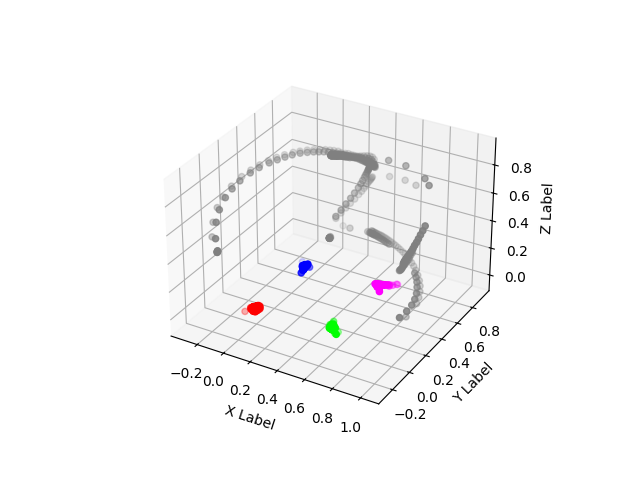

In [13]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt

fig = plt.figure()
ax = fig.add_subplot(projection='3d')

marker_poses_0 = np.array(aruco_dict_before[0])
marker_poses_1 = np.array(aruco_dict_before[1])
marker_poses_2 = np.array(aruco_dict_before[2])
marker_poses_3 = np.array(aruco_dict_before[3])
camera_path = np.array(camera_path_before)

start = 0
num = -1

ax.scatter(marker_poses_0[start:num, 0, 3], marker_poses_0[start:num, 1, 3], marker_poses_0[start:num, 2, 3], c=[(1, 0, 0, 1) for i in range(len(marker_poses_0[start:num, 2, 3]))])
ax.scatter(marker_poses_1[start:num, 0, 3], marker_poses_1[start:num, 1, 3], marker_poses_1[start:num, 2, 3], c=[(0, 1, 0, 1) for i in range(len(marker_poses_1[start:num, 2, 3]))])
ax.scatter(marker_poses_2[start:num, 0, 3], marker_poses_2[start:num, 1, 3], marker_poses_2[start:num, 2, 3], c=[(0, 0, 1, 1) for i in range(len(marker_poses_2[start:num, 2, 3]))])
ax.scatter(marker_poses_3[start:num, 0, 3], marker_poses_3[start:num, 1, 3], marker_poses_3[start:num, 2, 3], c=[(1, 0, 1, 1) for i in range(len(marker_poses_3[start:num, 2, 3]))])
ax.scatter(camera_path[:, 0, 3], camera_path[:, 1, 3], camera_path[:, 2, 3], c=[(0.5, 0.5, 0.5, 1) for i in range(len(camera_path))])

marker_poses_0 = np.array(aruco_dict_after[0])
marker_poses_1 = np.array(aruco_dict_after[1])
marker_poses_2 = np.array(aruco_dict_after[2])
marker_poses_3 = np.array(aruco_dict_after[3])
camera_path = np.array(camera_path_after)

start = 0
num = -1

ax.scatter(marker_poses_0[start:num, 0, 3], marker_poses_0[start:num, 1, 3], marker_poses_0[start:num, 2, 3], c=[(1, 0, 0, 0.5) for i in range(len(marker_poses_0[start:num, 2, 3]))])
ax.scatter(marker_poses_1[start:num, 0, 3], marker_poses_1[start:num, 1, 3], marker_poses_1[start:num, 2, 3], c=[(0, 1, 0, 0.5) for i in range(len(marker_poses_1[start:num, 2, 3]))])
ax.scatter(marker_poses_2[start:num, 0, 3], marker_poses_2[start:num, 1, 3], marker_poses_2[start:num, 2, 3], c=[(0, 0, 1, 0.5) for i in range(len(marker_poses_2[start:num, 2, 3]))])
ax.scatter(marker_poses_3[start:num, 0, 3], marker_poses_3[start:num, 1, 3], marker_poses_3[start:num, 2, 3], c=[(1, 0, 1, 0.5) for i in range(len(marker_poses_3[start:num, 2, 3]))])
ax.scatter(camera_path[:, 0, 3], camera_path[:, 1, 3], camera_path[:, 2, 3], c=[(0.5, 0.5, 0.5, 0.5) for i in range(len(camera_path))])

print(np.sum(np.diff(marker_poses_2[:, :3, 3], axis=0), axis=0))

ax.set_xlabel('X Label')
ax.set_ylabel('Y Label')
ax.set_zlabel('Z Label')

# ax.set_xlim(-1, 1)
# ax.set_ylim(-1, 1)
# ax.set_zlim(-1, 1)

plt.autoscale(False)
plt.show()